In [1]:
import torch 
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset,DataLoader
from PIL import Image
from sklearn.datasets import load_iris
import numpy as np ; import pandas as pd
from sklearn.model_selection import train_test_split
from typing import  List,Tuple,Dict
from torchmetrics.classification import MulticlassPrecision, MulticlassRecall


#
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
generator = torch.Generator(device=device)
torch.set_default_device(device=device)




/home/linux/miniconda3/envs/P_3_11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
class MyDataset(Dataset):
    def __init__(self,X:np.array,y:np.array,type_of_problem='classification'):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
        self.num_of_samples = y.shape[0]
        if type_of_problem =='classification':
            self.class_balance = np.unique(y,return_counts=True)
    @property
    def class_weights(self):
        #num_of_classes = len(self.class_balance[0])
        weights = (self.class_balance[1])/np.sum(self.class_balance[1])
        return weights
    def __getitem__(self, index):
        return (self.X[index],self.y[index])
    def __len__(self):
        return self.num_of_samples        

In [11]:
class MyDataSplitter:
    def __call__(self,X,y,split_size=0.7):
        train_idx,test_idx = torch.utils.data.random_split(range(y.shape[0]),[split_size,1-split_size])
        print(list(train_idx))
        return MyDataset(X[train_idx],y[train_idx]) , MyDataset(X[test_idx],y[test_idx])
    
        

In [91]:
class CNN_network(torch.nn.Module):
    def __init__(self,num_of_conv_layers=3,num_of_filters=4,channel_in=1,filter_size=3,stride=1,padding=0,pool_size=2,num_of_linear_layers=3,num_of_classes=2,image_width=32):
        super().__init__()
        self.num_of_classes = num_of_classes
        cnn_layers = [torch.nn.Conv2d(channel_in,num_of_filters,filter_size,stride,padding),torch.nn.ReLU(),torch.nn.MaxPool2d(pool_size),torch.nn.Dropout2d(0.2)]
        
        for i in range(0,num_of_conv_layers-1):
            cnn_layers.append(torch.nn.Conv2d(num_of_filters,num_of_filters,filter_size,stride,padding))
            cnn_layers.append(torch.nn.BatchNorm2d(num_of_filters))
            cnn_layers.append(torch.nn.Tanh())
            cnn_layers.append(torch.nn.AvgPool2d(pool_size))
            cnn_layers.append(torch.nn.Dropout2d(0.35))        
        
        mlp_layer = []
    
        num_of_hidden_neurons = int((image_width*num_of_filters)*1.5)
        mlp_layer.append(torch.nn.Flatten(start_dim=1))

        if num_of_linear_layers>1:
            mlp_layer.append(
                torch.nn.LazyLinear(num_of_hidden_neurons)
            )
            mlp_layer.append(torch.nn.ReLU())
            num_of_linear_layers-=1

        for i in range(0,num_of_linear_layers-1,1):
            mlp_layer.append(torch.nn.Linear(num_of_hidden_neurons,num_of_hidden_neurons))
            mlp_layer.append(torch.nn.BatchNorm1d(num_of_hidden_neurons))
            mlp_layer.append(torch.nn.Tanh())
            mlp_layer.append(torch.nn.Dropout(0.35))
        
        mlp_layer.append(
            torch.nn.LazyLinear(num_of_classes)
        )
        self.network = torch.nn.Sequential(*cnn_layers,*mlp_layer)
    def forward(self,X):
        return self.network(X)
    def predict(self,X):
        logits = self(X)
        return torch.argmax(logits,dim=1)
    
    def train_model(self,trainDataLoader:torch.utils.data.DataLoader,optimizer:torch.optim.Optimizer,lr:float=0.1,epochs=100)->List[float]:
        self.train()
        optimizer = optimizer(self.network.parameters(),lr=lr)
        #l_s:torch.optim.lr_scheduler.ReduceLROnPlateau = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,'min')
        loss_function:torch.nn.CrossEntropyLoss = torch.nn.CrossEntropyLoss()
        errors_avgs = []
        errors = []
        for epoch in range(epochs):
            errors.clear()
            for batch in trainDataLoader:
                inputs = batch[0].to(device)
                targets = batch[1].to(device)
                optimizer.zero_grad()
                logits = self(inputs)
                loss = loss_function(logits,targets)

                errors.append(loss.item())

                loss.backward()
                optimizer.step()
            print(f'-{epoch}-')
            errors_avgs.append(sum(errors)/len(errors))
            #l_s.step(errors_avgs[-1])

        return errors_avgs
    def eval_model(self,testDataloader:torch.utils.data.DataLoader):

        self.eval()

        precision = MulticlassPrecision(num_classes=self.num_of_classes).to(device=device)
        recall = MulticlassRecall(num_classes=self.num_of_classes).to(device=device)

        
        with torch.no_grad():

            for batch in testDataloader:
                inputs = batch[0].to(device)
                targets = batch[1].to(device)
                preds = self.predict(inputs)
                
                precision.update(preds=preds,target=targets)
                recall.update(preds=preds,target=targets)

        total_precision = precision.compute().item()
        total_recall = recall.compute().item()
        
        print(f"Evaluation - Precision: {total_precision:.4f}, Recall: {total_recall:.4f}")
        
        return precision, recall





In [92]:
transformer= torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((32, 32)),
        torchvision.transforms.ToTensor(),
        torchvision.transforms.Normalize((.5,),(.5,))
    ]
)

transformer_2 = torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((32, 32)),
        torchvision.transforms.RandomRotation(36),
        torchvision.transforms.ToTensor(),
        torchvision.transforms.Normalize((.5,),(.5,))
    ]
)

In [93]:
train_dataset= torchvision.datasets.FashionMNIST(root='./fashionMnist',download=True,train=True,transform=transformer)
test_dataset = torchvision.datasets.FashionMNIST(root='./fashionMnist',download=True,train=False,transform=transformer)

In [94]:
len(train_dataset)

60000

In [95]:
train_dataloader = torch.utils.data.DataLoader(train_dataset,batch_size=75,shuffle=True,generator=generator,num_workers=0)
test_dataloader = torch.utils.data.DataLoader(test_dataset,batch_size=75,shuffle=True,generator=generator,num_workers=0)


In [98]:
model = CNN_network(num_of_conv_layers=2,filter_size=3,num_of_filters=12,pool_size=2,num_of_linear_layers=5,channel_in=1,padding=1,image_width=32,num_of_classes = 10)

In [99]:
results = model.train_model(train_dataloader,torch.optim.AdamW,epochs=75,lr=0.01)

-0-
-1-
-2-
-3-
-4-
-5-
-6-
-7-
-8-
-9-
-10-
-11-
-12-
-13-
-14-
-15-
-16-
-17-
-18-
-19-
-20-
-21-
-22-
-23-
-24-
-25-
-26-
-27-
-28-
-29-
-30-
-31-
-32-
-33-
-34-
-35-
-36-
-37-
-38-
-39-
-40-
-41-
-42-
-43-
-44-
-45-
-46-
-47-
-48-
-49-
-50-
-51-
-52-
-53-
-54-
-55-
-56-
-57-
-58-
-59-
-60-
-61-
-62-
-63-
-64-
-65-
-66-
-67-
-68-
-69-
-70-
-71-
-72-
-73-
-74-


In [100]:
import matplotlib.pyplot as plt 

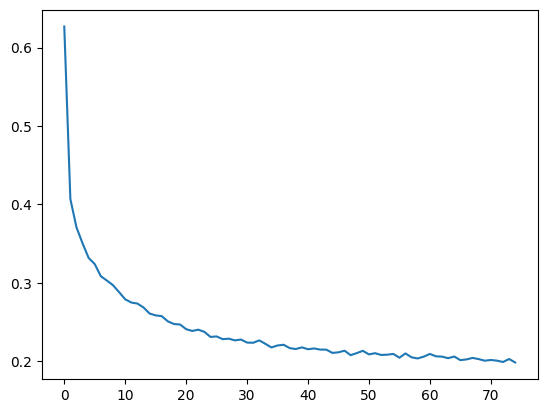

In [101]:
plt.plot(results)

In [104]:
p,r = model.eval_model(train_dataloader)

Evaluation - Precision: 0.9555, Recall: 0.9521


In [103]:
for i in range(10):
    print(f"Class {i}: Precision={p[i]:.4f}, Recall={r[i]:.4f}")

TypeError: unsupported format string passed to CompositionalMetric.__format__